# Part 5 — Open-Ended Image Retrieval

This notebook compares BoVW, VLAD, Fisher Vectors, ResNet-18, DINOv2, and CLIP using the saved manifests and feature caches. Image queries and CLIP text prompts are evaluated separately against the same validation corpus. Query images are excluded from that corpus. CLIP uses broad motorbike class relevance for prompt sensitivity; its scores do not evaluate whether an image is actually red, cropped, or zoomed.

Run from the `code/` directory. The deep image embeddings and handcrafted encodings are loaded from the existing caches; this notebook does not re-extract the full dataset.


In [1]:
from pathlib import Path
import importlib.util
from time import perf_counter
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Support running with either the notebook directory or repository root as cwd.
PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / "data").is_dir() and (PROJECT_DIR / "code" / "data").is_dir():
    PROJECT_DIR = PROJECT_DIR / "code"
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

# Load this notebook's exact helper file, avoiding a stale/other `src` package in sys.modules.
retrieval_path = PROJECT_DIR / 'src' / 'retrieval.py'
retrieval_spec = importlib.util.spec_from_file_location('src.retrieval', retrieval_path)
retrieval = importlib.util.module_from_spec(retrieval_spec)
sys.modules['src.retrieval'] = retrieval
retrieval_spec.loader.exec_module(retrieval)
print(f'Retrieval helpers loaded from: {retrieval_path.resolve()}')
print(f'Category-aware feature loader: {"filename_categories" in retrieval.load_handcrafted_features.__code__.co_varnames}')

DATA_DIR = PROJECT_DIR / "data"
RETRIEVAL_DIR = DATA_DIR / "retrieval"
RESULTS_DIR = PROJECT_DIR / "results" / "part5"
FIGURES_DIR = RESULTS_DIR / "figures"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
print(f"Project directory: {PROJECT_DIR.resolve()}")
print(f"Results directory: {RESULTS_DIR.resolve()}")


Retrieval helpers loaded from: /home/luis/Desktop/iacv_labs/assignment2/code/src/retrieval.py
Category-aware feature loader: True
Project directory: /home/luis/Desktop/iacv_labs/assignment2/code
Results directory: /home/luis/Desktop/iacv_labs/assignment2/code/results/part5


## 1. Load and validate the shared evaluation set

The manifests define five motorbike image queries, the held-out retrieval corpus, and binary relevance labels. Any query/corpus overlap or missing image is an error.


In [2]:
queries = retrieval.load_queries(RETRIEVAL_DIR / "image_queries.csv")
corpus = retrieval.load_corpus(RETRIEVAL_DIR / "corpus.csv")
relevance = retrieval.load_relevance(RETRIEVAL_DIR / "relevance.csv")
prompts = retrieval.load_clip_prompts(RETRIEVAL_DIR / "clip_prompts.csv")

retrieval.validate_manifests(queries, corpus, relevance)
retrieval.validate_image_files(queries["filename"].tolist(), DATA_DIR / "images")
retrieval.validate_image_files(corpus["filename"].tolist(), DATA_DIR / "images")

assert set(queries.filename).isdisjoint(set(corpus.filename)), "Query images must be excluded from the corpus"
print(f"Image queries: {len(queries)} | corpus images: {len(corpus)}")
print(f"Categories in corpus: {corpus.category.value_counts().to_dict()}")
display(queries)
display(prompts)


Image queries: 5 | corpus images: 2469
Categories in corpus: {'background': 1077, 'person': 886, 'car': 229, 'aeroplane': 126, 'motorbike': 120, 'horse': 31}


,query_id,filename,notes
0,Q1,004191,"Portrait orientation (0.66 AR), likely close-u..."
1,Q2,002567,"Standard 4:3 landscape (1.33 AR), typical side..."
2,Q3,007314,"Standard 4:3 landscape (1.33 AR), mid-list div..."
3,Q4,004647,"Wide 3:2 landscape (1.50 AR), possibly wider s..."
4,Q5,002082,"Widest aspect ratio (1.66 AR), likely panorami..."


,prompt_id,prompt_text,detail_level,transform,attribute
0,L1_motorcycle,a motorcycle,1,NaN,NaN
1,L1_motorbike,a motorbike,1,NaN,NaN
2,L2_photo,a photo of a motorcycle,2,photo,NaN
3,L2_cropped,a cropped image of a motorcycle,2,cropped,NaN
4,L2_zoomed,a zoomed-in image of a motorcycle,2,zoomed,NaN
5,L2_side_view,a side view of a motorcycle,2,side_view,NaN
6,L3_red_cropped,a cropped image of a red motorcycle,3,cropped,red
7,L3_red_zoomed,a zoomed-in image of a red motorcycle,3,zoomed,red
8,L3_black_photo,a photo of a black motorcycle,3,photo,black
9,L3_parked_photo,a photo of a parked motorcycle,3,photo,parked


## 2. Load aligned features and evaluate image-query methods

Every feature source is aligned by filename to avoid relying on archive row order. The same relevance judgments and corpus order are used for all five image-query methods.


In [3]:
# Reload helper source in this cell too, so rerunning it picks up the current loader implementation.
retrieval_spec = importlib.util.spec_from_file_location("src.retrieval", PROJECT_DIR / "src" / "retrieval.py")
retrieval = importlib.util.module_from_spec(retrieval_spec)
sys.modules["src.retrieval"] = retrieval
retrieval_spec.loader.exec_module(retrieval)

query_names = queries["filename"].astype(str).tolist()
corpus_names = corpus["filename"].astype(str).tolist()
all_names = query_names + corpus_names
query_ids = queries["query_id"].astype(str).tolist()
relevance_vectors = retrieval.build_relevance_vectors(queries, corpus, relevance)
filename_categories = dict(zip(corpus['filename'].astype(str), corpus['category'].astype(str)))
filename_categories.update(dict.fromkeys(query_names, 'motorbike'))

handcrafted = {
    "BoVW": ("bovw_K512_C0", "bovw_K512_C0"),
    "VLAD": ("vlad_K32_C80", "vlad_K32_C80"),
    "Fisher Vector": ("fv_K32_C80", "fv_K32_C80"),
}
deep = {
    "ResNet-18": "resnet18",
    "DINOv2": "dinov2_vits14",
}

method_metrics = []
method_rankings = []
method_costs = []

for display_name, (encoding_name, _) in handcrafted.items():
    full_features = retrieval.load_handcrafted_features(
        encoding_name, all_names, data_dir=DATA_DIR,
        filename_categories=filename_categories,
    )
    q_features = full_features[:len(query_names)]
    c_features = full_features[len(query_names):]
    metrics, rankings = retrieval.run_retrieval(
        q_features, c_features, corpus_names, relevance_vectors, query_ids,
        method_name=display_name,
    )
    method_metrics.append(metrics)
    method_rankings.append(rankings)
    archive_files = list((DATA_DIR / "encodings" / encoding_name).glob("*_val.npz"))
    storage = retrieval.measure_storage(archive_files)
    method_costs.append({
        "method": display_name,
        "feature_dim": int(full_features.shape[1]),
        "val_feature_storage_MiB": storage["storage_MiB"],
        "val_feature_extraction_s": np.nan,  # original extraction duration was not recorded in these archives
    })

for display_name, model_name in deep.items():
    full_features = retrieval.load_deep_features_aligned(
        model_name, all_names, data_dir=DATA_DIR
    )
    q_features = full_features[:len(query_names)]
    c_features = full_features[len(query_names):]
    metrics, rankings = retrieval.run_retrieval(
        q_features, c_features, corpus_names, relevance_vectors, query_ids,
        method_name=display_name,
    )
    method_metrics.append(metrics)
    method_rankings.append(rankings)
    cache_path = DATA_DIR / "deep_features" / f"{model_name}_features.npz"
    with np.load(cache_path, allow_pickle=True) as saved:
        extraction_s = float(saved["val_extract_seconds"]) if "val_extract_seconds" in saved.files else np.nan
    storage = retrieval.measure_storage([cache_path])
    method_costs.append({
        "method": display_name,
        "feature_dim": int(full_features.shape[1]),
        "val_feature_storage_MiB": storage["storage_MiB"],
        "val_feature_extraction_s": extraction_s,
    })

image_metrics = pd.concat(method_metrics, ignore_index=True)
image_rankings = pd.concat(method_rankings, ignore_index=True)
image_summary = image_metrics[image_metrics.query_id.astype(str) == "mAP"].copy()
display(image_summary[["method", "AP", "P@5", "P@10", "P@20", "R@5", "R@10", "R@20", "feature_dim", "query_time_s"]].round(4))

# Per-query AP makes query sensitivity visible, beyond the aggregate mAP.
image_query_ap = image_metrics[image_metrics.query_id.astype(str) != "mAP"].pivot(
    index="query_id", columns="method", values="AP"
)
display(image_query_ap.round(4))


,method,AP,P@5,P@10,P@20,R@5,R@10,R@20,feature_dim,query_time_s
5,BoVW,0.0500,0.08,0.06,0.05,0.0033,0.0050,0.0083,2048,0.0014
11,VLAD,0.0636,0.08,0.10,0.09,0.0033,0.0083,0.0150,10240,0.0056
17,Fisher Vector,0.0449,0.12,0.08,0.06,0.0050,0.0067,0.0100,20608,0.0134
23,ResNet-18,0.5298,0.88,0.90,0.83,0.0367,0.0750,0.1383,896,0.0044
29,DINOv2,0.7862,0.96,0.98,0.96,0.0400,0.0817,0.1600,384,0.0016


## 3. Evaluate CLIP text-to-image prompt sensitivity

CLIP reuses the cached validation image embeddings. The text encoder is loaded through `src.deep_models.getModel`, matching the project’s established model-loading path. CLIP relevance here is motorbike category membership for every prompt, so Level 2/3 scores measure prompt sensitivity against broad labels, not attribute correctness.


In [4]:
clip_image_features = retrieval.load_clip_image_features_aligned(
    corpus_names, data_dir=DATA_DIR
)
clip_feature_path = DATA_DIR / "deep_features" / "clip_vit_b_32_val_images.npz"
with np.load(clip_feature_path, allow_pickle=True) as saved:
    clip_extract_s = float(saved["extract_seconds"])

# Use the same project's CLIP loader and preprocessing source; image vectors are already cached.
import torch
from src.deep_models import getModel

device = "cuda" if torch.cuda.is_available() else "cpu"
clip_model, _ = getModel("clip_vit_b_32", device=device, nofc=True)
start = perf_counter()
clip_prompt_ids, clip_text_features = retrieval.encode_clip_text_queries(
    prompts, clip_model, device=device, batch_size=32
)
clip_text_encode_s = perf_counter() - start

# Broad relevance: all motorbike corpus images are positive for each text prompt.
clip_relevance = pd.DataFrame(
    [
        {"query_id": prompt_id, "filename": filename,
         "relevant": int(category == "motorbike")}
        for prompt_id in clip_prompt_ids
        for filename, category in zip(corpus_names, corpus.category.astype(str))
    ]
)
clip_query_manifest = prompts.rename(columns={"prompt_id": "query_id"})
clip_relevance_vectors = retrieval.build_relevance_vectors(
    clip_query_manifest, corpus, clip_relevance
)
clip_metrics, clip_rankings = retrieval.run_retrieval(
    clip_text_features, clip_image_features, corpus_names,
    clip_relevance_vectors, clip_prompt_ids, method_name="CLIP text-to-image",
)

# The mAP row here is the mean AP over prompts; each prompt AP is also retained.
clip_prompt_results = clip_metrics[clip_metrics.query_id.astype(str) != "mAP"].merge(
    prompts[["prompt_id", "prompt_text", "detail_level", "transform", "attribute"]],
    left_on="query_id", right_on="prompt_id", how="left",
)
display(clip_prompt_results[["prompt_id", "detail_level", "prompt_text", "AP", "P@5", "P@10", "P@20", "R@5", "R@10", "R@20"]].round(4))
clip_storage = retrieval.measure_storage([clip_feature_path])
method_costs.append({
    "method": "CLIP text-to-image",
    "feature_dim": int(clip_image_features.shape[1]),
    "val_feature_storage_MiB": clip_storage["storage_MiB"],
    "val_feature_extraction_s": clip_extract_s,
    "text_prompt_encoding_s": clip_text_encode_s,
})

clip_level_summary = clip_prompt_results.groupby("detail_level", as_index=False).agg(
    mean_AP=("AP", "mean"), mean_P_at_5=("P@5", "mean"),
    mean_P_at_10=("P@10", "mean"), mean_P_at_20=("P@20", "mean"),
    mean_R_at_20=("R@20", "mean"), prompt_count=("prompt_id", "count"),
)
display(clip_level_summary.round(4))


/home/luis/Desktop/iacv_labs/.venv/lib/python3.11/site-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


,prompt_id,detail_level,prompt_text,AP,P@5,P@10,P@20,R@5,R@10,R@20
0,L1_motorcycle,1,a motorcycle,0.8610,1.0,1.0,1.00,0.0417,0.0833,0.1667
1,L1_motorbike,1,a motorbike,0.8359,1.0,1.0,0.90,0.0417,0.0833,0.1500
2,L2_photo,2,a photo of a motorcycle,0.8678,1.0,1.0,1.00,0.0417,0.0833,0.1667
3,L2_cropped,2,a cropped image of a motorcycle,0.9019,1.0,1.0,1.00,0.0417,0.0833,0.1667
4,L2_zoomed,2,a zoomed-in image of a motorcycle,0.8613,1.0,1.0,0.95,0.0417,0.0833,0.1583
5,L2_side_view,2,a side view of a motorcycle,0.8389,1.0,1.0,1.00,0.0417,0.0833,0.1667
6,L3_red_cropped,3,a cropped image of a red motorcycle,0.8066,1.0,1.0,1.00,0.0417,0.0833,0.1667
7,L3_red_zoomed,3,a zoomed-in image of a red motorcycle,0.7122,1.0,0.9,0.85,0.0417,0.0750,0.1417
8,L3_black_photo,3,a photo of a black motorcycle,0.8022,1.0,1.0,1.00,0.0417,0.0833,0.1667
9,L3_parked_photo,3,a photo of a parked motorcycle,0.7858,1.0,1.0,1.00,0.0417,0.0833,0.1667


## 4. Save metric tables, full rankings, and costs

The result tables keep each query’s AP and top-K metrics, plus an aggregate row per image method. CLIP prompt-level APs are retained independently. Cached extraction time is reported only when present in the cache; older handcrafted archives do not record that timing.


In [5]:
all_metrics = pd.concat([image_metrics, clip_metrics], ignore_index=True)
all_rankings = pd.concat([image_rankings, clip_rankings], ignore_index=True)

# One common export plus method-specific files for convenient inspection.
all_metrics.to_csv(RESULTS_DIR / "metrics_all.csv", index=False)
all_rankings.to_csv(RESULTS_DIR / "rankings_all.csv", index=False)
for method_name in all_rankings.method.unique():
    retrieval.save_retrieval_outputs(
        all_metrics[all_metrics.method == method_name],
        all_rankings[all_rankings.method == method_name],
        method_name,
        output_dir=RESULTS_DIR,
    )

costs = pd.DataFrame(method_costs)
# Join measured per-query ranking time from each method's aggregate row.
query_times = all_metrics[all_metrics.query_id.astype(str) == "mAP"][["method", "query_time_s", "query_time_total_s"]]
costs = costs.merge(query_times, on="method", how="left")
costs.to_csv(RESULTS_DIR / "costs.csv", index=False)

summary = all_metrics[all_metrics.query_id.astype(str) == "mAP"].copy()
summary = summary[["method", "AP", "P@5", "P@10", "P@20", "R@5", "R@10", "R@20", "feature_dim", "query_time_s"]]
summary = summary.rename(columns={"AP": "mean_AP_over_queries_or_prompts"})
summary.to_csv(RESULTS_DIR / "summary.csv", index=False)
display(summary.round(4))
display(costs.round(4))
print(f"Saved tables under {RESULTS_DIR.resolve()}")


,method,mean_AP_over_queries_or_prompts,P@5,P@10,P@20,R@5,R@10,R@20,feature_dim,query_time_s
5,BoVW,0.0500,0.08,0.06,0.05,0.0033,0.0050,0.0083,2048,0.0014
11,VLAD,0.0636,0.08,0.10,0.09,0.0033,0.0083,0.0150,10240,0.0056
17,Fisher Vector,0.0449,0.12,0.08,0.06,0.0050,0.0067,0.0100,20608,0.0134
23,ResNet-18,0.5298,0.88,0.90,0.83,0.0367,0.0750,0.1383,896,0.0044
29,DINOv2,0.7862,0.96,0.98,0.96,0.0400,0.0817,0.1600,384,0.0016
40,CLIP text-to-image,0.8274,1.00,0.99,0.97,0.0417,0.0825,0.1617,512,0.0012


,method,feature_dim,val_feature_storage_MiB,val_feature_extraction_s,text_prompt_encoding_s,query_time_s,query_time_total_s
0,BoVW,2048,5.9954,NaN,NaN,0.0014,0.0072
1,VLAD,10240,99.9380,NaN,NaN,0.0056,0.0278
2,Fisher Vector,20608,419.1685,NaN,NaN,0.0134,0.0671
3,ResNet-18,896,17.3659,167.3914,NaN,0.0044,0.0222
4,DINOv2,384,7.6127,427.2892,NaN,0.0016,0.0080
5,CLIP text-to-image,512,5.0728,253.6254,0.4175,0.0012,0.0125


Saved tables under /home/luis/Desktop/iacv_labs/assignment2/code/results/part5


## 5. Compare results and inspect success/failure examples

The bar chart compares mean AP for image queries and mean prompt AP for CLIP. The two query modalities are distinct, so interpret CLIP as a separate prompt-sensitivity result. For each method, the next cell saves the highest-AP and lowest-AP query examples; green borders mark relevant results and red borders mark irrelevant results.


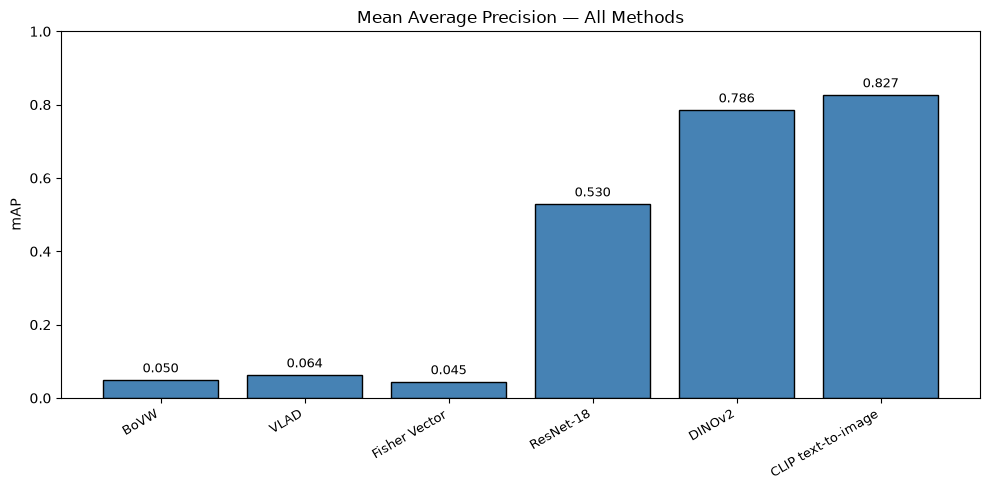

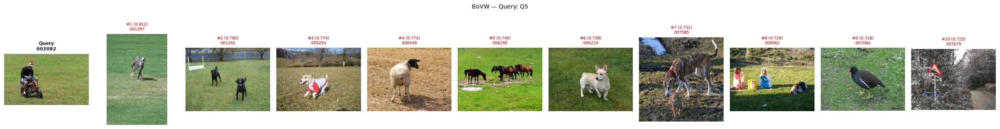

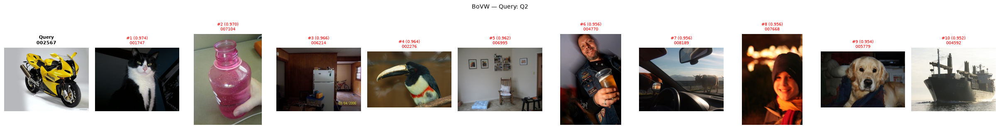

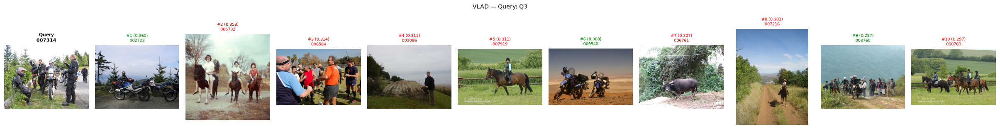

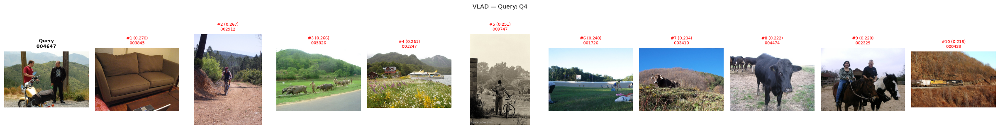

...

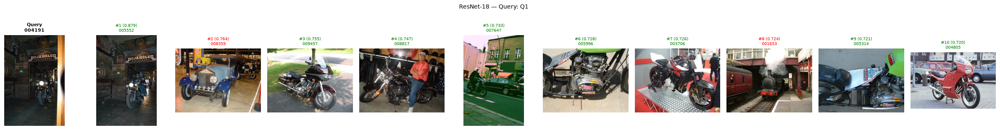

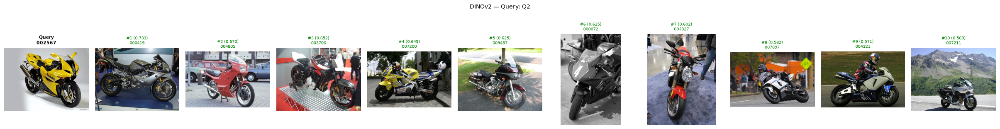

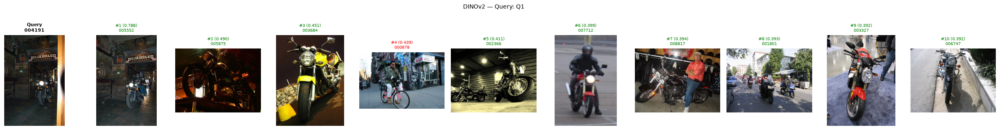

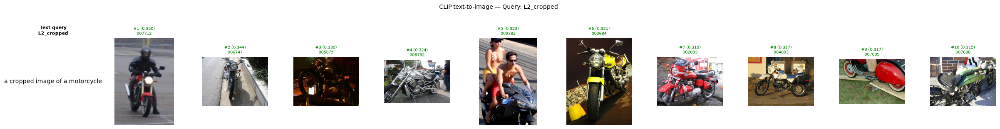

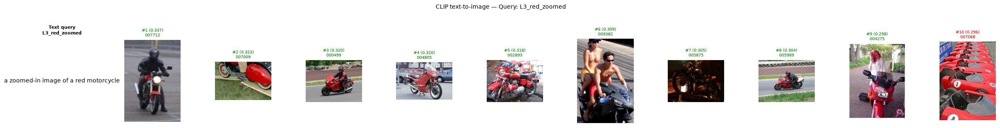

In [6]:
fig = retrieval.plot_metrics_comparison(all_metrics)
fig.savefig(FIGURES_DIR / "map_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

# Keep a compact visual audit: best and worst query/prompt for each method.
image_query_lookup = queries.set_index("query_id")["filename"].to_dict()
prompt_lookup = prompts.set_index("prompt_id")["prompt_text"].to_dict()
per_query = all_metrics[all_metrics.query_id.astype(str) != "mAP"]
for method_name, group in per_query.groupby("method", sort=False):
    best = group.loc[group.AP.idxmax()]
    worst = group.loc[group.AP.idxmin()]
    for label, row in (("best", best), ("worst", worst)):
        qid = str(row.query_id)
        query_filename = image_query_lookup.get(qid)
        query_text = prompt_lookup.get(qid)
        fig = retrieval.plot_top_results(
            query_id=qid,
            query_filename=query_filename,
            query_text=query_text,
            rankings_df=all_rankings,
            method_name=method_name,
            top_k=10,
            img_dir=DATA_DIR / "images",
            save_path=FIGURES_DIR / f"{method_name.replace(' ', '_')}_{label}_{qid}.png",
        )
        plt.show()
        plt.close(fig)


## Part 5 questions — answers and evidence

### 1. Which retrieval strategy provides the best results for the selected category?

**Question:** Which retrieval strategy provides the best results for the selected category? Support your answer with quantitative metrics and representative retrieval examples.

**Answer:** Averaged over the ten fixed CLIP prompts, CLIP text-to-image has mean AP **0.827**. Among image-query methods, DINOv2 is strongest, with mAP **0.786**. These are different query modalities, so report them separately. The highest individual prompt AP is **0.902** for “a cropped image of a motorcycle”; because it is the best of ten prompts after inspecting these results, treat it as prompt-sensitivity evidence rather than an unbiased final score.

**Evidence:** The summary table reports AP, P@K, and R@K. The CLIP prompt table reports each prompt’s AP; the level summary reports mean AP by detail level. The notebook saves best and worst example rankings for each method under `results/part5/figures/`. DINOv2’s image-query mAP is 0.786; CLIP’s mean AP over prompts is 0.827; its top individual prompt AP is 0.902.

### 2. How do local visual patterns compare with global deep embeddings?

**Question:** How does retrieval based on local visual patterns (BoVW or VLAD) compare with retrieval based on global deep embeddings (CNN or DINOv2)?

**Answer:** The global pretrained embeddings perform substantially better on this corpus and query set. DINOv2 reaches mAP **0.786** and ResNet-18 **0.530**, compared with VLAD **0.064**, BoVW **0.050**, and Fisher Vector **0.045**. The local encodings’ dimensions do not compensate for their lower ranking quality here.

**Evidence:** These are the per-method aggregate AP values in the image-query summary table, computed over the same five queries and corpus with cosine similarity and the same relevance vectors. Inspect the saved best/worst retrieval figures to see the corresponding rankings.

### 3. Does increasing vocabulary size improve retrieval, and can PCA retain retrieval performance?

**Question:** Does increasing the visual vocabulary size improve retrieval quality? Can PCA reduce descriptor dimensionality while retaining retrieval performance?

**Answer:** This experiment cannot answer either comparison. It uses one BoVW vocabulary size (K=512), one VLAD setting (K=32, C=80), and one Fisher Vector setting (K=32, C=80). There is no controlled vocabulary-size sweep or PCA-on versus PCA-off pair, so the results do not show a causal effect of vocabulary size or PCA.

**Evidence:** The feature dimensions in the comparison are BoVW 2,048, VLAD 10,240, and Fisher Vector 20,608. Each method has only the single saved configuration used by the notebook. To answer this, train multiple vocabulary sizes and PCA settings using training descriptors, encode the same queries and corpus, and evaluate with the same relevance labels.

### 4. How does query diversity affect retrieval performance?

**Question:** How does the diversity of query images affect retrieval performance? Compare results using different queries or query sets, including visually similar and substantially different examples.

**Answer:** Results vary substantially by query, showing that retrieval quality is sensitive to the selected query image. DINOv2 AP ranges from **0.603 (Q1)** to **0.865 (Q2)**; ResNet-18 ranges from **0.364 (Q1)** to **0.710 (Q5)**. This notebook evaluates five different motorbike queries individually, but it does not run a controlled comparison between alternative query sets, so it cannot attribute those differences specifically to diversity.

**Evidence:** The per-query AP pivot table and query manifest show the five query results and their recorded aspect-ratio/viewpoint notes. For DINOv2 and ResNet-18, the AP ranges above are from that table. The best/worst figures show how the rankings change across queries.

### 5. How sensitive is CLIP retrieval to prompt wording and detail?

**Question:** For CLIP, how sensitive is text-to-image retrieval to the wording of the query? Does a more detailed description improve the ranking?

**Answer:** CLIP is wording-sensitive, and added detail does not consistently improve AP. Mean AP is **0.848** for Level 1, **0.867** for Level 2, and **0.777** for Level 3. The “cropped image” Level 2 prompt reaches AP **0.902**, while “zoomed-in image of a red motorcycle” reaches **0.712**. So Level 2 does best on average in this prompt set, but increasing detail to Level 3 lowers mean AP.

**Evidence:** These values come from the CLIP prompt AP table and the grouped detail-level summary. Relevance is broad motorbike category membership for every prompt; there are no red/cropped/zoomed annotations. The numbers measure prompt effects on broad-category ranking, not attribute retrieval accuracy.

### 6. What are the limitations of evaluating retrieval on this corpus?

**Question:** What are the limitations of evaluating retrieval on a small corpus? Discuss corpus size, ground-truth completeness, class imbalance, and near-duplicate images.

**Answer:** The corpus has **2,469** images and **120** motorbike positives per query (about 4.9%), so results depend on this particular class mix and validation subset. Labels are image-level category labels; they do not judge whether a motorbike is red, cropped, or shown from a particular viewpoint. Query images are excluded from the corpus and exact filename overlap is checked, but this notebook does not run a perceptual near-duplicate audit. Near duplicates could therefore make scores optimistic. The five queries and one fixed corpus also provide limited evidence about performance on other images or larger collections.

**Evidence:** The corpus manifest contains 1,077 background, 886 person, 229 car, 126 aeroplane, 120 motorbike, and 31 horse images. The relevance vectors contain 120 positives for each query. The manifest checks ensure exact query filenames do not occur in the corpus; no perceptual-hash or manual near-duplicate results are recorded.
